# EDA и бинарная классификация на датасете «Титаник»

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 1:** Введение в Data Science и EDA  
**Датасет:** Titanic  

**Выполнил:** Толмачев Виталий Владимирович 
**Группа:** ПКТб-23-1  
**Преподаватель:** Спирин Игорь Сергеевич  

**Ссылка на репозиторий:** https://github.com/Dittalik/ml-course-tolmachev.git
**Путь к модулю:** `module-1-titanic/notebook.ipynb`  
**Дата сдачи:** 2026-29-10

## Введение

**Задача:** бинарная классификация — предсказать, выжил ли пассажир Titanic (0 — не выжил, 1 — выжил).

**Что такое ML-проект:** ML-проект включает в себя все этапы разработки решения на основе машинного обучения. Работа начинается с постановки задачи и анализа данных, после чего выполняются их подготовка, исследовательский анализ (EDA) и формирование признаков. Далее происходит обучение моделей, подбор наиболее подходящих вариантов и оценка их качества. Завершающим этапом является применение готовой модели. При этом процесс обычно носит итеративный характер: результаты оценки могут показать необходимость вернуться к предыдущим этапам и изменить подготовку данных или признаки.

**Почему классификация, а не регрессия:** Целевая переменная имеет два фиксированных значения: пассажир либо выжил, либо нет. Поэтому задача относится к бинарной классификации. В отличие от неё, регрессия применяется в случаях, когда необходимо предсказать непрерывное числовое значение, например стоимость недвижимости или температуру. Классификационная модель же определяет принадлежность объекта к одной из заранее заданных категорий.

**Какая метрика важнее:** Для данной задачи основной метрикой можно считать ROC-AUC. Она показывает, насколько хорошо модель способна отличать выживших пассажиров от погибших и ранжировать их по вероятности выживания, не привязываясь к конкретному порогу классификации. Кроме того, эта метрика хорошо подходит для задач, где классы могут быть представлены неравномерно.
Если необходимо оценить работу модели при конкретном пороге, полезно использовать F1-score. Эта метрика учитывает одновременно Precision и Recall, поэтому позволяет получить более сбалансированную оценку, чем Accuracy, которая при дисбалансе классов может выглядеть высокой даже у не слишком качественной модели.

**Цель работы:**
1. Провести полный EDA датасета Титаник.
2. Обучить 2+ модели и достичь ROC-AUC ≥ 0.80.
3. Реализовать функцию предсказания для нового пассажира.

## Теоретическая часть

### 1. EDA (Exploratory Data Analysis)
EDA — это первичный анализ данных перед построением модели машинного обучения. Он нужен, чтобы понять структуру датасета, типы признаков и обнаружить закономерности или проблемы. На этом этапе проверяют пропуски, выбросы, дубликаты и распределения признаков. Также изучают взаимосвязи между признаками с помощью статистики и визуализаций. В результате становится понятно, какие данные нужно подготовить перед обучением модели.

---

### 2. Пропуски (NaN)
Пропуски возникают, когда значение не было записано, потерялось или неприменимо для конкретного объекта. Их наличие может мешать работе некоторых алгоритмов машинного обучения. Пропуски можно удалить, если их немного и удаление не приведёт к потере важной информации. Также их можно заменить средним, медианой, модой или другим подходящим значением. Выбор стратегии зависит от типа данных и причины появления пропусков.

---

### 3. Кодирование категориальных признаков
Label Encoding заменяет категории числами, например мужчина = 0, женщина = 1. Он подходит для категорий, между которыми существует естественный порядок, но может создать ложное представление о величине. One-Hot Encoding создаёт отдельный бинарный признак для каждой категории. Он лучше подходит для номинальных категорий, между которыми нет порядка.

---

### 4. Масштабирование признаков
StandardScaler преобразует признаки так, чтобы они имели среднее значение 0 и стандартное отклонение 1. MinMaxScaler масштабирует значения в заданный диапазон, чаще всего от 0 до 1. StandardScaler часто используют для алгоритмов, чувствительных к масштабу и распределению данных. MinMaxScaler удобен, когда требуется ограничить значения признаков определённым диапазоном.

---

### 5. Feature Engineering
Feature Engineering — это создание новых признаков или преобразование существующих для улучшения качества модели. Новые признаки могут лучше отражать закономерности в данных, чем исходные. Например, из даты рождения можно получить возраст, а из роста и веса — индекс массы тела. Хорошо подобранные признаки могут повысить точность модели и упростить обучение.

---

### 6. Метрики классификации
Accuracy показывает долю правильных предсказаний среди всех объектов. Precision показывает, какая доля объектов, отнесённых моделью к положительному классу, действительно является положительной. Recall показывает, какую долю всех реальных положительных объектов модель смогла найти. F1-score — это гармоническое среднее Precision и Recall, поэтому он полезен при необходимости учитывать обе метрики одновременно. ROC-AUC оценивает способность модели различать положительный и отрицательный классы при разных порогах классификации. Чем ближе ROC-AUC к 1, тем лучше модель разделяет классы.

**Основные формулы метрик:**

$$Accuracy = \frac{TP + TN}{TP + TN + FP + FN}$$

$$Precision = \frac{TP}{TP + FP} \quad \quad Recall = \frac{TP}{TP + FN}$$

$$F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$$


In [1]:
import pandas as pd

# Загрузка датасета Titanic (train и test)
train_df = pd.read_csv('./data/train.csv')
test_df = pd.read_csv('./data/test.csv')

# Вывод размеров обучающей и тестовой выборок
print(train_df.shape, test_df.shape)

(891, 12) (418, 11)


## Описание данных

**Источник:** [Kaggle Titanic: Machine Learning from Disaster](https://www.kaggle.com/c/titanic)

**Структура:**
- Всего примеров в train: 891
- Всего примеров в test: 418
- Признаков: 11 (+ целевая `Survived`)
- Числовых признаков: 6 (`PassengerId`, `Pclass`, `Age`, `SibSp`, `Parch`, `Fare`)
- Категориальных признаков: 5 (`Name`, `Sex`, `Ticket`, `Cabin`, `Embarked`)

**Описание столбцов:**
| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| PassengerId | int64 | Уникальный ID пассажира | 0% |
| Survived | int64 (0/1) | Целевая переменная: выжил (1) или погиб (0) | 0% |
| Pclass | int64 (1/2/3) | Класс билета (1 = 1-й, 2 = 2-й, 3 = 3-й) | 0% |
| Name | object | Имя и титул пассажира | 0% |
| Sex | object | Пол пассажира (male / female) | 0% |
| Age | float64 | Возраст пассажира в годах | 19.87% |
| SibSp | int64 | Количество братьев/сестер/супругов на борту | 0% |
| Parch | int64 | Количество родителей/детей на борту | 0% |
| Ticket | object | Номер билета | 0% |
| Fare | float64 | Стоимость билета (тариф) | 0% |
| Cabin | object | Номер каюты | 77.10% |
| Embarked | object | Порт посадки (C = Cherbourg, Q = Queenstown, S = Southampton) | 0.22% |

**Распределение классов:**
- Не выжило (0): 549 (61.6%)
- Выжило (1): 342 (38.4%)

**Файл данных в репозитории:** `module-1-titanic/data/titanic_info.md`

## Подготовка данных и EDA

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

# Задаём оформление будущих графиков
sns.set_theme(style="ticks", palette="deep")
plt.rcParams["font.size"] = 10

# 1. Читаем обучающие и тестовые данные из папки data
train_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

# 2. Проверяем количество строк и столбцов в обоих наборах
print("=== Информация о размерах данных ===")
print(f"Обучающая выборка: {train_df.shape}")
print(f"Тестовая выборка: {test_df.shape}")

# 3. Просматриваем начало обучающей таблицы
print("\n=== Пример данных ===")
display(train_df.head())

# 4. Изучаем типы признаков и заполненность столбцов
print("\n=== Структура обучающего набора ===")
train_df.info()

# 5. Получаем основные статистические показатели числовых столбцов
print("\n=== Описательная статистика ===")
display(train_df.describe())

# 6. Находим пропущенные значения и рассчитываем их долю
nan_count = train_df.isna().sum()
nan_percent = (nan_count / train_df.shape[0] * 100).round(2)

# Объединяем информацию о пропусках в одну таблицу
nan_report = pd.DataFrame({
    "Пропущено значений": nan_count,
    "Доля пропусков, %": nan_percent
})

# Оставляем в отчёте только столбцы с пропусками
nan_report = nan_report[nan_report["Пропущено значений"] > 0]

# Выводим результаты анализа пропусков
print("\n=== Отчёт по пропущенным данным ===")
display(nan_report.sort_values(
    by="Пропущено значений",
    ascending=False
))

# 7. Выбираем числовые признаки для анализа распределений
numeric_features = train_df.select_dtypes(
    include=np.number
)

# Рассчитываем асимметрию и эксцесс каждого числового признака
distribution_report = pd.DataFrame({
    "Асимметрия": numeric_features.skew().round(3),
    "Эксцесс": numeric_features.kurtosis().round(3)
})

# Выводим характеристики распределений
print("\n=== Статистика распределений ===")
display(distribution_report)

# 8. Исследуем соотношение выживших и погибших пассажиров
survival_counts = train_df["Survived"].value_counts()
survival_share = train_df["Survived"].value_counts(normalize=True) * 100

# Собираем абсолютные и относительные частоты в одну таблицу
survival_report = pd.DataFrame({
    "Количество пассажиров": survival_counts,
    "Доля, %": survival_share.round(2)
})

# Задаём понятные названия категорий
survival_report.index = survival_report.index.map({
    0: "Погибли",
    1: "Выжили"
})

# Выводим распределение целевой переменной
print("\n=== Распределение выживаемости ===")
display(survival_report)

=== Информация о размерах данных ===
Обучающая выборка: (891, 12)
Тестовая выборка: (418, 11)

=== Пример данных ===


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



=== Структура обучающего набора ===
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

=== Описательная статистика ===


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



=== Отчёт по пропущенным данным ===


,Пропущено значений,"Доля пропусков, %"
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22



=== Статистика распределений ===


,Асимметрия,Эксцесс
PassengerId,0.000,-1.200
Survived,0.479,-1.775
Pclass,-0.631,-1.280
Age,0.389,0.178
SibSp,3.695,17.880
Parch,2.749,9.778
Fare,4.787,33.398



=== Распределение выживаемости ===


,Количество пассажиров,"Доля, %"
Survived,,
Погибли,549,61.62
Выжили,342,38.38


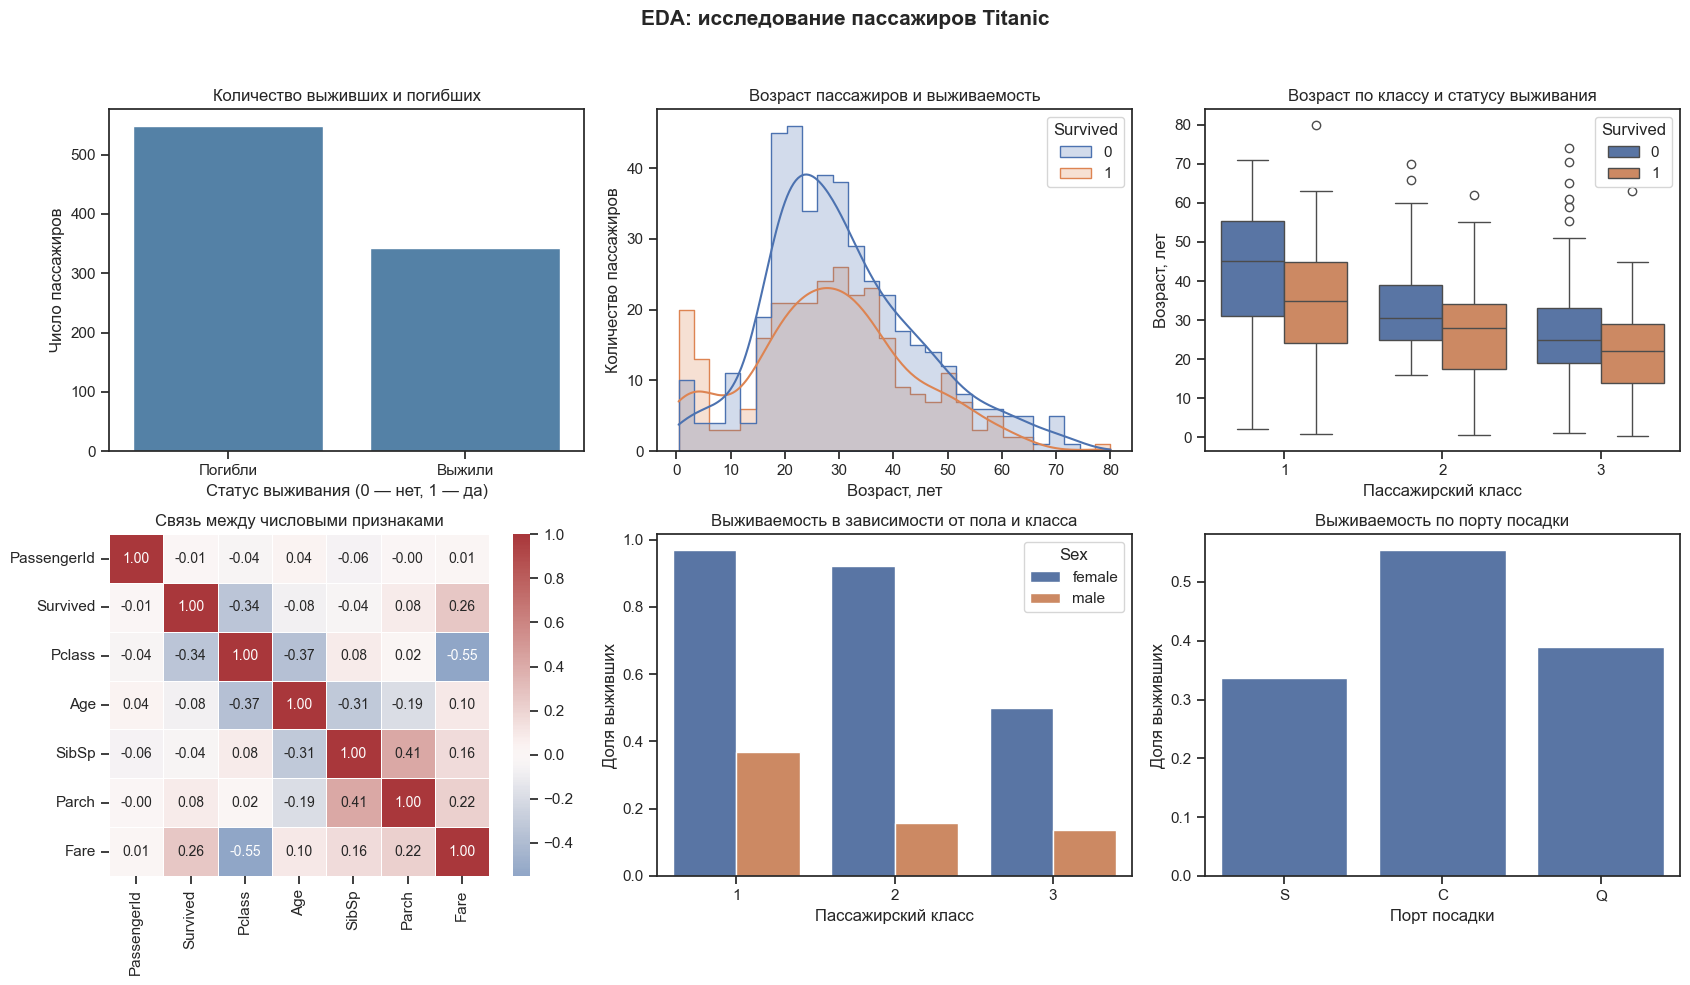

In [4]:
# Формируем область с шестью графиками в два ряда
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(17, 10))

# Добавляем общий заголовок для всей визуализации
fig.suptitle("EDA: исследование пассажиров Titanic", fontsize=15, fontweight="semibold")


# 1. Распределение пассажиров по факту выживания
sns.countplot(
    data=train_df,
    x="Survived",
    ax=ax[0, 0],
    color="steelblue"
)

# Настраиваем подписи и заголовок первого графика
ax[0, 0].set_title("Количество выживших и погибших")
ax[0, 0].set_xlabel("Статус выживания (0 — нет, 1 — да)")
ax[0, 0].set_ylabel("Число пассажиров")
ax[0, 0].set_xticks([0, 1], ["Погибли", "Выжили"])


# 2. Распределение возрастов с учётом выживаемости
sns.histplot(
    data=train_df,
    x="Age",
    hue="Survived",
    bins=28,
    kde=True,
    element="step",
    ax=ax[0, 1]
)

# Оформляем второй график
ax[0, 1].set_title("Возраст пассажиров и выживаемость")
ax[0, 1].set_xlabel("Возраст, лет")
ax[0, 1].set_ylabel("Количество пассажиров")


# 3. Сравнение возраста пассажиров разных классов
sns.boxplot(
    data=train_df,
    x="Pclass",
    y="Age",
    hue="Survived",
    ax=ax[0, 2]
)

# Добавляем поясняющие подписи
ax[0, 2].set_title("Возраст по классу и статусу выживания")
ax[0, 2].set_xlabel("Пассажирский класс")
ax[0, 2].set_ylabel("Возраст, лет")


# 4. Вычисляем корреляции между числовыми признаками
numeric_data = train_df.select_dtypes(include="number")
corr = numeric_data.corr()

# Отображаем корреляционную матрицу в виде тепловой карты
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    linewidths=0.4,
    ax=ax[1, 0]
)

# Подписываем тепловую карту
ax[1, 0].set_title("Связь между числовыми признаками")


# 5. Сравниваем долю выживших в зависимости от пола и класса
sns.barplot(
    data=train_df,
    x="Pclass",
    y="Survived",
    hue="Sex",
    errorbar=None,
    ax=ax[1, 1]
)

# Настраиваем пятый график
ax[1, 1].set_title("Выживаемость в зависимости от пола и класса")
ax[1, 1].set_xlabel("Пассажирский класс")
ax[1, 1].set_ylabel("Доля выживших")


# 6. Анализируем выживаемость в зависимости от порта посадки
sns.barplot(
    data=train_df,
    x="Embarked",
    y="Survived",
    errorbar=None,
    ax=ax[1, 2]
)

# Добавляем заголовок и подписи осей
ax[1, 2].set_title("Выживаемость по порту посадки")
ax[1, 2].set_xlabel("Порт посадки")
ax[1, 2].set_ylabel("Доля выживших")


# Автоматически регулируем расстояния между графиками
plt.tight_layout(rect=[0, 0, 1, 0.95])

# Отображаем итоговую сетку графиков
plt.show()

### Выводы по результатам разведочного анализа данных (EDA)

1. **Распределение целевой переменной (`Survived`):**  
   Анализ первого графика показывает, что погибших пассажиров было больше, чем выживших. Доля погибших составляет примерно 61,6%, а выживших — 38,4%. Поэтому при построении модели важно оценивать не только Accuracy, но и такие метрики, как F1-score и ROC-AUC.

2. **Зависимость выживаемости от возраста (`Age`):**  
   Гистограмма показывает различия в распределении возраста среди выживших и погибших. Среди выживших заметна представленность маленьких детей, что может указывать на приоритет их спасения. При этом возраст сам по себе не определял исход для каждого пассажира.

3. **Возраст пассажиров в разных классах (`Pclass`):**  
   Boxplot демонстрирует, что пассажиры первого класса в целом были старше пассажиров второго и третьего классов. Медианный возраст приблизительно составляет 37, 29 и 24 года соответственно. Это подтверждает целесообразность заполнения пропусков в `Age` медианой внутри групп, сформированных по классу пассажира и полу.

4. **Взаимосвязь числовых признаков (`Heatmap`):**  
   Корреляционная матрица показывает положительную связь между выживаемостью и стоимостью билета `Fare` (около 0,26), а также отрицательную связь между `Survived` и `Pclass` (около −0,34). Между `Pclass` и `Fare` наблюдается более выраженная отрицательная корреляция (около −0,55). Это означает, что пассажиры более высокого класса обычно платили за билеты больше и чаще выживали.

5. **Влияние пола и класса обслуживания (`Sex` и `Pclass`):**  
   Пятый график показывает существенные различия в выживаемости между мужчинами и женщинами. Наиболее высокая доля выживших наблюдается среди женщин первого и второго классов. Мужчины третьего класса, напротив, имели значительно меньшую вероятность выживания. Следовательно, пол и класс пассажира являются важными признаками для прогнозирования результата.

6. **Влияние порта посадки (`Embarked`):**  
   По последнему графику можно заметить, что наиболее высокая доля выживших наблюдается среди пассажиров, севших в порту `C` (Cherbourg). Одним из возможных объяснений является более высокая доля пассажиров первого класса среди них. Однако порт посадки может отражать и другие особенности состава пассажиров, поэтому эту связь не следует считать причинно-следственной.

### Обоснование выбранных стратегий обработки пропущенных значений

**1. Признак `Age` — заполнение медианой по группам `Pclass` и `Sex`**

Пропущенные значения возраста заменяются медианой пассажиров с таким же классом обслуживания и полом. Такой подход учитывает различия в возрастном составе между мужчинами и женщинами, а также пассажирами разных классов. Медиана менее чувствительна к выбросам, чем среднее арифметическое. Если в отдельной группе все значения возраста отсутствуют, используется общая медиана возраста в качестве резервного варианта.

**2. Признак `Embarked` — заполнение модой**

Пропущенные значения порта посадки заменяются наиболее часто встречающейся категорией. Поскольку `Embarked` является категориальным признаком, использование среднего или медианы для него невозможно. Заполнение модой позволяет сохранить строки датасета и использовать признак при дальнейшем обучении модели. Недостаток метода заключается в том, что он может увеличить долю наиболее распространённой категории.

**3. Признак `Cabin` — удаление столбца**

Столбец `Cabin` удаляется из-за большого количества пропущенных значений. Восстановление номеров кают для большинства пассажиров было бы ненадёжным и могло бы внести ошибки в данные. Удаление столбца упрощает дальнейшую обработку и исключает необходимость заполнять значительную часть неизвестных значений. При этом потенциально полезная информация о каютах теряется, поэтому в более сложной модели можно рассмотреть извлечение палубы из имеющихся номеров кают до удаления столбца.

In [5]:
# Создаем копию исходного датасета для обработки данных
df_clean = train_df.copy()

# -------------------------------------------------------------------------
# 1. ОБРАБОТКА ПРОПУСКОВ
# -------------------------------------------------------------------------

# Рассчитываем медиану возраста отдельно для каждой группы по классу и полу
age_medians = df_clean.groupby(['Pclass', 'Sex'])['Age'].transform('median')

# Заполняем пропуски медианой соответствующей группы
df_clean['Age'] = df_clean['Age'].fillna(age_medians)

# Заполняем возможные оставшиеся пропуски возраста общей медианой
df_clean['Age'] = df_clean['Age'].fillna(train_df['Age'].median())

# Находим наиболее часто встречающееся значение порта посадки
embarked_mode = df_clean['Embarked'].mode()[0]

# Заполняем пропуски в Embarked наиболее частым значением
df_clean['Embarked'] = df_clean['Embarked'].fillna(embarked_mode)

# Удаляем Cabin из-за большого количества пропущенных значений
df_clean = df_clean.drop(columns=['Cabin'])

# Выводим количество оставшихся пропусков в столбцах
print("=== Проверка пропусков после обработки ===")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

# -------------------------------------------------------------------------
# 2. FEATURE ENGINEERING — СОЗДАНИЕ НОВЫХ ПРИЗНАКОВ
# -------------------------------------------------------------------------

# Рассчитываем размер семьи с учетом самого пассажира
df_clean['Family_Size'] = df_clean['SibSp'] + df_clean['Parch'] + 1

# Создаем бинарный признак: 1 — пассажир один, 0 — путешествует с семьей
df_clean['Is_Alone'] = (df_clean['Family_Size'] == 1).astype(int)

# Разделяем возраст на пять категорий с помощью заданных границ
df_clean['Age_Group'] = pd.cut(
    df_clean['Age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Child', 'Teenager', 'Young_Adult', 'Adult', 'Senior'],
    include_lowest=True
)

# Выводим первые строки новых признаков для проверки
print("\n=== Созданные признаки ===")
print(df_clean[['Family_Size', 'Is_Alone', 'Age_Group']].head())

# -------------------------------------------------------------------------
# 3. КОДИРОВАНИЕ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ
# -------------------------------------------------------------------------

# Создаем объект для кодирования категориального признака
le = LabelEncoder()

# Преобразуем пол в числовые значения: female — 0, male — 1
df_clean['Sex'] = le.fit_transform(df_clean['Sex'])

# Преобразуем Embarked в отдельные бинарные столбцы
df_clean = pd.get_dummies(
    df_clean,
    columns=['Embarked'],
    drop_first=False,
    dtype=int
)

# Выводим список столбцов итогового датасета
print("\n=== Итоговые столбцы ===")
print(df_clean.columns.tolist())

# Выводим первые три строки обработанного датасета
print("\n=== Первые три строки ===")
print(df_clean.head(3))


=== Проверка пропусков после обработки ===
Series([], dtype: int64)

=== Созданные признаки ===
   Family_Size  Is_Alone    Age_Group
0            2         0  Young_Adult
1            2         0        Adult
2            1         1  Young_Adult
3            2         0  Young_Adult
4            1         1  Young_Adult

=== Итоговые столбцы ===
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Family_Size', 'Is_Alone', 'Age_Group', 'Embarked_C', 'Embarked_Q', 'Embarked_S']

=== Первые три строки ===
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   

                                                Name  Sex   Age  SibSp  Parch  \
0                            Braund, Mr. Owen Harris    1  22.0      1      0   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...    0  38.0      1      0   
2                             Heikkinen, Miss. Laina    0

## Построение и обучение моделей

In [6]:
# Импортируем модуль для измерения времени выполнения
import time

# Импортируем функцию для разделения данных
from sklearn.model_selection import train_test_split

# Импортируем инструмент для масштабирования признаков
from sklearn.preprocessing import StandardScaler

# Импортируем модели машинного обучения
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# -------------------------------------------------------------------------
# 1. ВЫБОР ПРИЗНАКОВ
# -------------------------------------------------------------------------

# Указываем признаки, которые будут использоваться для обучения моделей
feature_cols = [
    'Pclass', 'Sex', 'Age', 'SibSp', 'Parch',
    'Fare', 'Family_Size', 'Is_Alone',
    'Embarked_Q', 'Embarked_S'
]

# Формируем таблицу входных признаков
X = df_clean[feature_cols]

# Выбираем целевую переменную: 0 — не выжил, 1 — выжил
y = df_clean['Survived']

# -------------------------------------------------------------------------
# 2. РАЗДЕЛЕНИЕ ДАННЫХ
# -------------------------------------------------------------------------

# Разделяем данные на обучающую и проверочную выборки в пропорции 80/20
# stratify сохраняет приблизительно одинаковое соотношение классов
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Выводим размеры полученных выборок
print("Размер обучающей выборки:", X_train.shape)
print("Размер проверочной выборки:", X_test.shape)

# -------------------------------------------------------------------------
# 3. МАСШТАБИРОВАНИЕ ПРИЗНАКОВ ДЛЯ LOGISTIC REGRESSION
# -------------------------------------------------------------------------

# Создаем объект для стандартизации числовых признаков
scaler = StandardScaler()

# Рассчитываем параметры масштабирования только на обучающих данных
X_train_scaled = scaler.fit_transform(X_train)

# Применяем те же параметры к проверочным данным
X_test_scaled = scaler.transform(X_test)

# -------------------------------------------------------------------------
# 4. ОБУЧЕНИЕ LOGISTIC REGRESSION
# -------------------------------------------------------------------------

# Создаем логистическую регрессию с L2-регуляризацией
lr_model = LogisticRegression(
    penalty='l2',
    C=1.0,
    max_iter=1000,
    random_state=42
)

# Засекаем время перед обучением модели
start_time = time.time()

# Обучаем модель на масштабированных признаках
lr_model.fit(X_train_scaled, y_train)

# Рассчитываем время обучения
lr_time = time.time() - start_time

# Выводим время обучения логистической регрессии
print(f"Время обучения Logistic Regression: {lr_time:.4f} секунд")

# -------------------------------------------------------------------------
# 5. ОБУЧЕНИЕ DECISION TREE
# -------------------------------------------------------------------------

# Создаем дерево решений с ограниченной глубиной
dt_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

# Засекаем время перед обучением дерева решений
start_time = time.time()

# Обучаем дерево на исходных, немасштабированных признаках
dt_model.fit(X_train, y_train)

# Рассчитываем время обучения дерева решений
dt_time = time.time() - start_time

# Выводим время обучения дерева решений
print(f"Время обучения Decision Tree: {dt_time:.4f} секунд")

# -------------------------------------------------------------------------
# 6. ДОПОЛНИТЕЛЬНАЯ МОДЕЛЬ: RANDOM FOREST
# -------------------------------------------------------------------------

# Создаем случайный лес из 100 деревьев с ограниченной глубиной
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

# Засекаем время перед обучением случайного леса
start_time = time.time()

# Обучаем случайный лес на исходных признаках
rf_model.fit(X_train, y_train)

# Рассчитываем время обучения случайного леса
rf_time = time.time() - start_time

# Выводим время обучения случайного леса
print(f"Время обучения Random Forest: {rf_time:.4f} секунд")

# -------------------------------------------------------------------------
# 7. ДОПОЛНИТЕЛЬНАЯ МОДЕЛЬ: GRADIENT BOOSTING
# -------------------------------------------------------------------------

# Создаем модель градиентного бустинга
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Засекаем время перед обучением градиентного бустинга
start_time = time.time()

# Обучаем модель на исходных признаках
gb_model.fit(X_train, y_train)

# Рассчитываем время обучения градиентного бустинга
gb_time = time.time() - start_time

# Выводим время обучения градиентного бустинга
print(f"Время обучения Gradient Boosting: {gb_time:.4f} секунд")

# -------------------------------------------------------------------------
# 8. СВОДНАЯ ТАБЛИЦА ВРЕМЕНИ ОБУЧЕНИЯ
# -------------------------------------------------------------------------

# Собираем названия моделей и время их обучения в таблицу
training_times = pd.DataFrame({
    'Модель': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting'
    ],
    'Время обучения (сек.)': [
        lr_time,
        dt_time,
        rf_time,
        gb_time
    ]
})

# Выводим результаты для сравнения
print("\n=== Время обучения моделей ===")
print(training_times.to_string(index=False))

Размер обучающей выборки: (712, 10)
Размер проверочной выборки: (179, 10)
Время обучения Logistic Regression: 0.0106 секунд
Время обучения Decision Tree: 0.0040 секунд
Время обучения Random Forest: 0.1830 секунд


c:\Users\vital\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Время обучения Gradient Boosting: 0.1594 секунд

=== Время обучения моделей ===
             Модель  Время обучения (сек.)
Logistic Regression               0.010558
      Decision Tree               0.003954
      Random Forest               0.182998
  Gradient Boosting               0.159384


## Модели

В ходе работы были обучены четыре алгоритма машинного обучения для решения задачи бинарной классификации пассажиров Titanic. Были рассмотрены две базовые модели — логистическая регрессия и решающее дерево, а также два ансамблевых алгоритма — случайный лес и градиентный бустинг.

| Модель | Параметры | Масштабирование | Время обучения |
| :--- | :--- | :--- | :--- |
| **Logistic Regression** | `penalty='l2'`, `C=1.0`, `max_iter=1000` | Да (`StandardScaler`) | 0.01055 сек |
| **Decision Tree** | `max_depth=5`, `min_samples_split=5`, `min_samples_leaf=2` | Нет | 0.00395 сек |
| **Random Forest** | `n_estimators=100`, `max_depth=5` | Нет | 0.18299 сек |
| **Gradient Boosting** | `n_estimators=100`, `learning_rate=0.1`, `max_depth=3` | Нет | 0.15938 сек |

Время обучения измерялось с помощью модуля `time`. Полученные значения зависят от оборудования и среды выполнения.

---

### Почему выбраны эти модели?

- **Logistic Regression (логистическая регрессия).** Используется в качестве базовой модели для сравнения качества предсказаний. Она оценивает вероятность принадлежности пассажира к классу выживших, относительно проста в интерпретации и позволяет анализировать влияние признаков через коэффициенты модели. Масштабирование признаков помогает улучшить процесс оптимизации.

- **Decision Tree (решающее дерево).** Нелинейная модель, которая выявляет зависимости между признаками с помощью последовательности условий. Например, при прогнозировании выживания могут учитываться пол, возраст и класс пассажира. Дерево не требует масштабирования признаков, а ограничение его глубины помогает уменьшить риск переобучения.

- **Random Forest (случайный лес).** Ансамблевый алгоритм, объединяющий предсказания множества деревьев решений. Благодаря усреднению результатов модель может снижать разброс предсказаний и лучше обобщать закономерности обучающей выборки.

- **Gradient Boosting (градиентный бустинг).** Ансамблевый алгоритм, при котором деревья обучаются последовательно. Каждая следующая модель стремится исправить ошибки предыдущих этапов, что позволяет выявлять более сложные зависимости в данных.

## Оценка качества

In [8]:
# Импортируем метрики для оценки качества классификации
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, roc_curve
)

# Создаем словарь с обученными моделями и соответствующими данными
models = {
    'Logistic Regression': (lr_model, X_test_scaled),
    'Decision Tree': (dt_model, X_test),
    'Random Forest': (rf_model, X_test),
    'Gradient Boosting': (gb_model, X_test)
}

# Создаем списки для сохранения метрик и предсказаний моделей
results = []
predictions = {}
probabilities = {}

# Перебираем все модели для оценки качества
for name, (model, X_eval) in models.items():

    # Получаем предсказанные классы пассажиров
    y_pred = model.predict(X_eval)

    # Получаем вероятности принадлежности к классу выживших
    y_proba = model.predict_proba(X_eval)[:, 1]

    # Сохраняем предсказания и вероятности для дальнейших графиков
    predictions[name] = y_pred
    probabilities[name] = y_proba

    # Рассчитываем основные метрики классификации
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_proba)

    # Добавляем результаты текущей модели в список
    results.append({
        'Модель': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1,
        'ROC-AUC': roc_auc
    })

    # Выводим подробный отчет по текущей модели
    print(f"\n=== {name} ===")
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")

    # Выводим отчет с метриками отдельно для каждого класса
    print("\nClassification report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=['Не выжил', 'Выжил'],
        zero_division=0
    ))

# Формируем итоговую таблицу сравнения моделей
results_df = pd.DataFrame(results)

# Сортируем модели по ROC-AUC от лучшей к худшей
results_df = results_df.sort_values(
    by='ROC-AUC',
    ascending=False
).reset_index(drop=True)

# Выводим таблицу с результатами всех моделей
print("\n=== Сравнение качества моделей ===")
print(results_df.round(4).to_string(index=False))


=== Logistic Regression ===
Accuracy:  0.8045
Precision: 0.7833
Recall:    0.6812
F1-score:  0.7287
ROC-AUC:   0.8486

Classification report:
              precision    recall  f1-score   support

    Не выжил       0.82      0.88      0.85       110
       Выжил       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179


=== Decision Tree ===
Accuracy:  0.7821
Precision: 0.7419
Recall:    0.6667
F1-score:  0.7023
ROC-AUC:   0.8132

Classification report:
              precision    recall  f1-score   support

    Не выжил       0.80      0.85      0.83       110
       Выжил       0.74      0.67      0.70        69

    accuracy                           0.78       179
   macro avg       0.77      0.76      0.77       179
weighted avg       0.78      0.78      0.78       179


=== Random Forest ===
Accuracy:  0.8212
Precision: 0.8491
Recall:

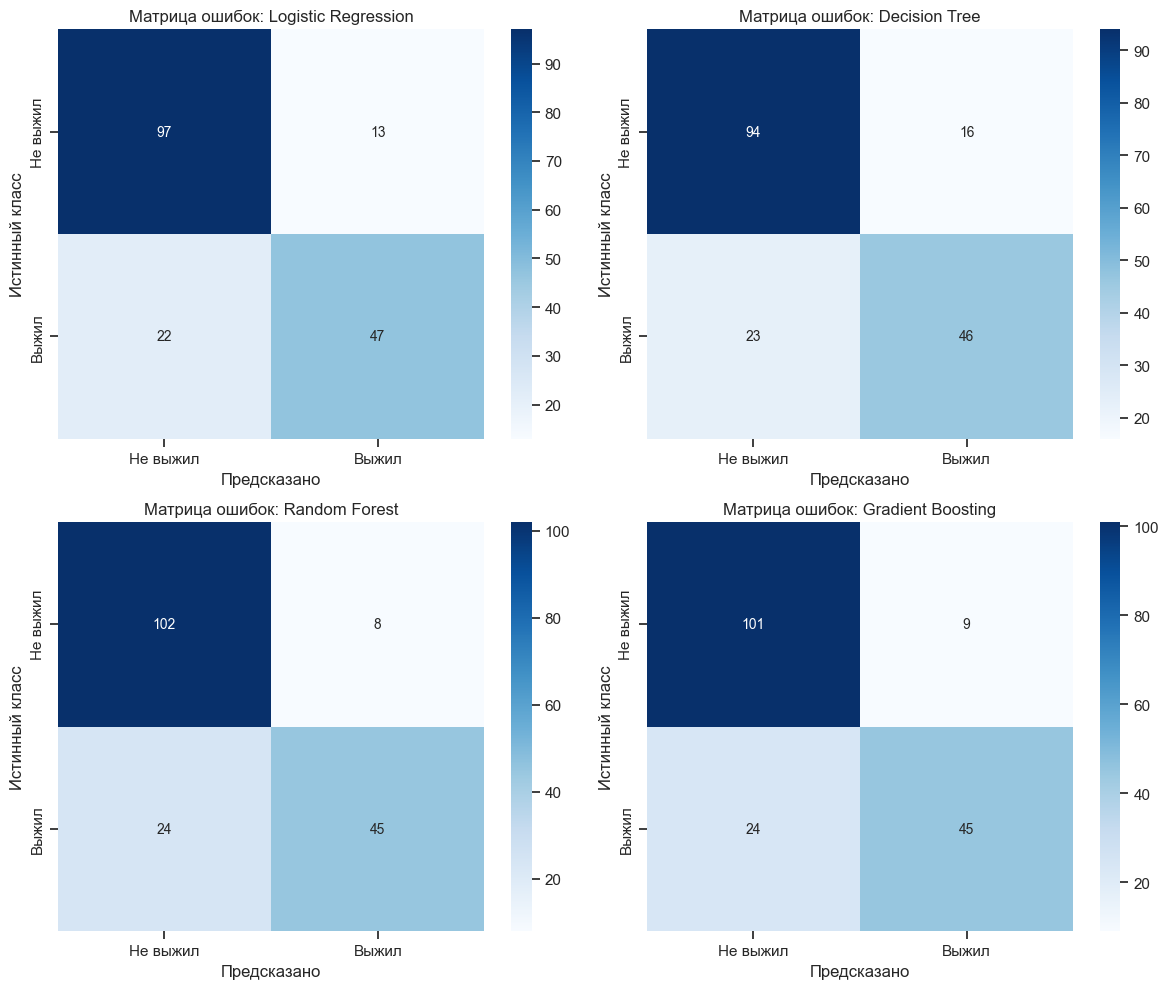

In [9]:
# Создаем фигуру для отображения матриц ошибок четырех моделей
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Преобразуем массив осей в одномерный список
axes = axes.flatten()

# Перебираем модели и соответствующие области графика
for ax, (name, y_pred) in zip(axes, predictions.items()):

    # Рассчитываем матрицу ошибок для текущей модели
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    # Отображаем матрицу ошибок в виде тепловой карты
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Не выжил', 'Выжил'],
        yticklabels=['Не выжил', 'Выжил'],
        ax=ax
    )

    # Подписываем ось X
    ax.set_xlabel('Предсказано')

    # Подписываем ось Y
    ax.set_ylabel('Истинный класс')

    # Добавляем заголовок с названием модели
    ax.set_title(f'Матрица ошибок: {name}')

# Настраиваем расположение графиков
plt.tight_layout()

# Отображаем все матрицы ошибок
plt.show()

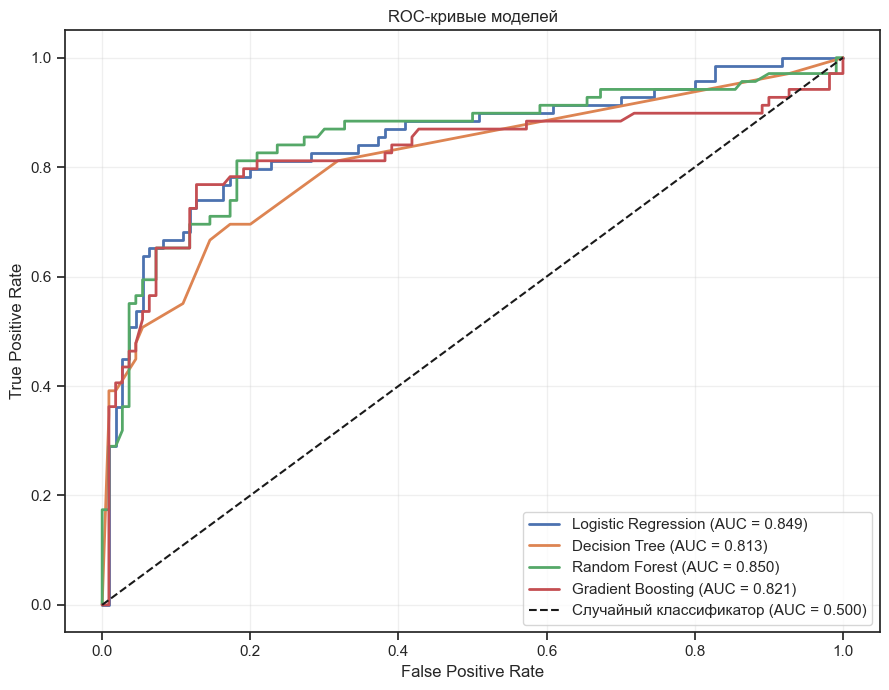

In [10]:
# Создаем фигуру для сравнения ROC-кривых
plt.figure(figsize=(9, 7))

# Перебираем модели для построения ROC-кривых
for name, y_proba in probabilities.items():

    # Рассчитываем долю ложноположительных и истинноположительных результатов
    fpr, tpr, thresholds = roc_curve(y_test, y_proba)

    # Рассчитываем площадь под ROC-кривой
    auc_value = roc_auc_score(y_test, y_proba)

    # Строим ROC-кривую с указанием значения AUC
    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc_value:.3f})',
        linewidth=2
    )

# Добавляем диагональ случайного классификатора
plt.plot(
    [0, 1],
    [0, 1],
    'k--',
    label='Случайный классификатор (AUC = 0.500)'
)

# Подписываем горизонтальную ось
plt.xlabel('False Positive Rate')

# Подписываем вертикальную ось
plt.ylabel('True Positive Rate')

# Добавляем заголовок графика
plt.title('ROC-кривые моделей')

# Отображаем легенду
plt.legend()

# Добавляем сетку для удобства анализа
plt.grid(alpha=0.3)

# Отображаем график
plt.tight_layout()
plt.show()

## Оценка качества моделей

Для сравнения моделей использовались пять метрик: Accuracy, Precision, Recall, F1-score и ROC-AUC. Дополнительно были построены матрицы ошибок и ROC-кривые.

### Значение метрик

- **Accuracy** — доля правильных предсказаний среди всех объектов.
- **Precision** — доля действительно выживших среди пассажиров, которых модель отнесла к выжившим.
- **Recall** — доля найденных моделью выживших среди всех пассажиров, которые действительно выжили.
- **F1-score** — гармоническое среднее Precision и Recall, позволяющее оценить их баланс.
- **ROC-AUC** — показатель способности модели различать два класса при различных порогах классификации. Значение около 0.5 соответствует случайному ранжированию, а более высокие значения указывают на лучшее разделение классов.

### Анализ результатов

Для определения наиболее подходящей модели необходимо рассмотреть значения всех метрик из итоговой таблицы.

- **Лучшая модель по ROC-AUC:** определяется по наибольшему значению ROC-AUC. Эта метрика позволяет сравнить способность моделей различать выживших и погибших независимо от одного фиксированного порога классификации.
- **Сравнение Accuracy и F1-score:** высокая Accuracy показывает хорошую общую точность, а F1-score помогает оценить баланс между Precision и Recall.
- **Анализ Precision и Recall:** если Precision выше Recall, модель реже ошибается, когда предсказывает выживание, но может пропускать больше действительно выживших пассажиров. Если Recall выше Precision, модель находит большую долю выживших, но чаще ошибочно относит к ним погибших.
- **Анализ матриц ошибок:** позволяет определить, какие ошибки преобладают у каждой модели, и сравнить количество верных и неверных предсказаний.
- **Сравнение моделей:** решающее дерево может выявлять нелинейные зависимости, но при чрезмерной глубине способно переобучаться. Случайный лес снижает разброс за счет объединения деревьев, а градиентный бустинг последовательно корректирует ошибки предыдущих моделей. Однако ни один из этих алгоритмов не гарантирует лучшего результата на конкретной выборке.

### Вывод

Итоговую модель следует выбирать по совокупности метрик, уделяя особое внимание ROC-AUC и F1-score, а также характеру ошибок в матрице ошибок. Наибольшее значение ROC-AUC указывает на лучшую способность различать классы, но не обязательно означает наибольшую Accuracy при стандартном пороге классификации 0.5. Окончательный вывод необходимо сделать на основе фактически полученных результатов.

## Интерпретация результатов

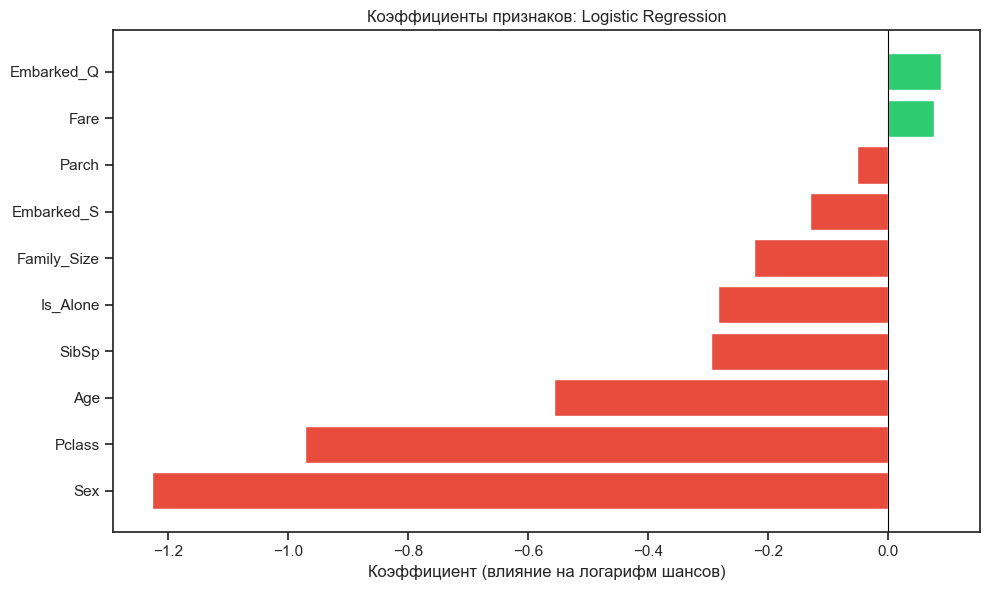

    Feature  Coefficient
        Sex    -1.225895
     Pclass    -0.971323
        Age    -0.557201
      SibSp    -0.294769
   Is_Alone    -0.283692
Family_Size    -0.223771
 Embarked_S    -0.129193
      Parch    -0.051203
       Fare     0.077219
 Embarked_Q     0.088102


In [11]:
# Создаем таблицу коэффициентов логистической регрессии
coefficients = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': lr_model.coef_[0]
})

# Сортируем коэффициенты по величине для удобства анализа
coefficients = coefficients.sort_values(
    by='Coefficient',
    ascending=True
)

# Назначаем зеленый цвет положительным коэффициентам и красный отрицательным
colors = [
    '#2ecc71' if value > 0 else '#e74c3c'
    for value in coefficients['Coefficient']
]

# Создаем область для графика коэффициентов
plt.figure(figsize=(10, 6))

# Строим горизонтальную диаграмму коэффициентов
plt.barh(
    coefficients['Feature'],
    coefficients['Coefficient'],
    color=colors
)

# Добавляем вертикальную линию нулевого коэффициента
plt.axvline(0, color='black', linewidth=0.8)

# Подписываем горизонтальную ось
plt.xlabel('Коэффициент (влияние на логарифм шансов)')

# Добавляем заголовок графика
plt.title('Коэффициенты признаков: Logistic Regression')

# Настраиваем расположение элементов графика
plt.tight_layout()

# Отображаем график
plt.show()

# Выводим таблицу коэффициентов
print(coefficients.to_string(index=False))

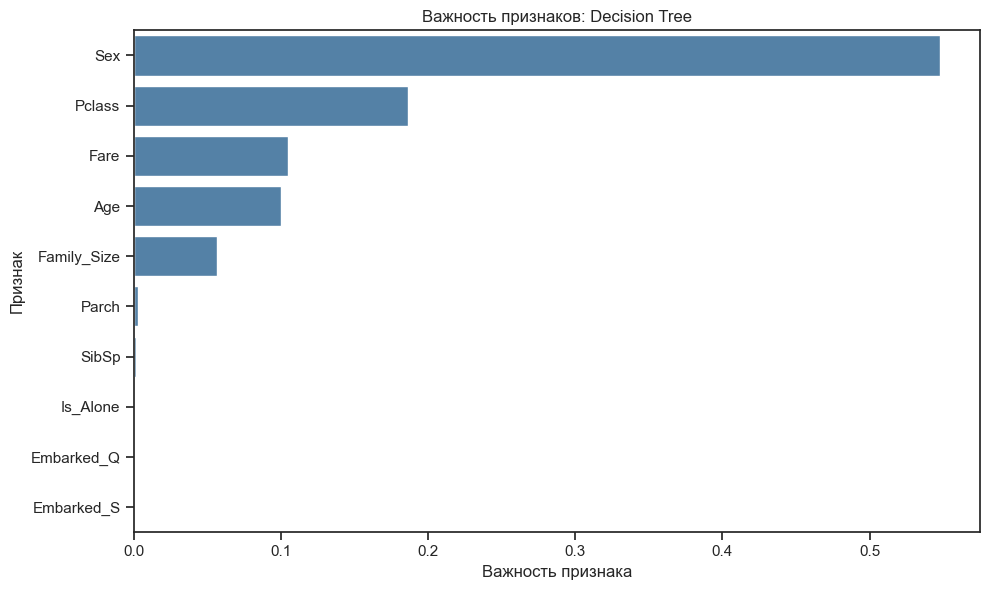

    Feature  Importance
        Sex    0.547662
     Pclass    0.186186
       Fare    0.105210
        Age    0.099922
Family_Size    0.056601
      Parch    0.002740
      SibSp    0.001678
   Is_Alone    0.000000
 Embarked_Q    0.000000
 Embarked_S    0.000000


In [12]:
# Создаем таблицу важности признаков решающего дерева
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': dt_model.feature_importances_
})

# Сортируем признаки от наиболее важных к наименее важным
importances = importances.sort_values(
    by='Importance',
    ascending=False
)

# Создаем область для диаграммы важности признаков
plt.figure(figsize=(10, 6))

# Строим горизонтальную диаграмму важности признаков
sns.barplot(
    data=importances,
    x='Importance',
    y='Feature',
    color='steelblue'
)

# Подписываем горизонтальную ось
plt.xlabel('Важность признака')

# Подписываем вертикальную ось
plt.ylabel('Признак')

# Добавляем заголовок графика
plt.title('Важность признаков: Decision Tree')

# Настраиваем расположение элементов
plt.tight_layout()

# Отображаем график
plt.show()

# Выводим таблицу важности признаков
print(importances.to_string(index=False))

In [13]:
# Рассчитываем долю выживших в зависимости от пола
survival_by_sex = train_df.groupby('Sex')['Survived'].mean() * 100

# Рассчитываем долю выживших в зависимости от класса пассажира
survival_by_class = train_df.groupby('Pclass')['Survived'].mean() * 100

# Создаем признак размера семьи в исходном датасете
family_size = train_df['SibSp'] + train_df['Parch'] + 1

# Рассчитываем долю выживших среди путешествовавших одних и с семьей
survival_by_alone = train_df.assign(
    Is_Alone=(family_size == 1).astype(int)
).groupby('Is_Alone')['Survived'].mean() * 100

# Выводим результаты по полу
print("=== Выживаемость по полу (%) ===")
print(survival_by_sex.round(2))

# Выводим результаты по классу пассажира
print("\n=== Выживаемость по классу (%) ===")
print(survival_by_class.round(2))

# Выводим результаты по наличию семьи
print("\n=== Выживаемость по наличию семьи (%) ===")
print(survival_by_alone.rename({
    0: 'Путешествовал с семьей',
    1: 'Путешествовал один'
}).round(2))

=== Выживаемость по полу (%) ===
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

=== Выживаемость по классу (%) ===
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64

=== Выживаемость по наличию семьи (%) ===
Is_Alone
Путешествовал с семьей    50.56
Путешествовал один        30.35
Name: Survived, dtype: float64


## Интерпретация результатов

### Коэффициенты Logistic Regression

Коэффициенты логистической регрессии позволяют оценить направление связи признаков с вероятностью выживания при прочих равных условиях.

- **Пол (`Sex`).** Поскольку женщины закодированы значением `0`, а мужчины — `1`, отрицательный коэффициент указывает на меньшие шансы выживания у мужчин относительно женщин.
- **Класс пассажира (`Pclass`).** Если коэффициент отрицательный, увеличение номера класса связано со снижением шансов выживания. Это согласуется с тем, что пассажиры третьего класса в среднем находились в менее благоприятном положении.
- **Стоимость билета (`Fare`).** Положительный коэффициент указывает на связь более высокой стоимости билета с увеличением шансов выживания при фиксированных остальных признаках.
- **Возраст (`Age`).** Знак коэффициента показывает направление связи возраста с предсказанием модели с учетом остальных признаков.
- **Размер семьи (`Family_Size`) и одиночное путешествие (`Is_Alone`).** Эти признаки позволяют исследовать связь состава семьи с выживанием.

Фактическое направление и величину коэффициентов следует проверять по построенному графику. Коррелирующие между собой признаки могут влиять на коэффициенты модели.

### Важность признаков Decision Tree

В решающем дереве важность признаков определяется тем, насколько сильно их использование в разделениях помогало модели различать выживших и погибших.

Наиболее важные признаки из построенного графика следует рассматривать как основные факторы, на которые опирается дерево при классификации. Результаты могут отличаться от логистической регрессии, поскольку дерево способно учитывать нелинейные зависимости и взаимодействия между признаками.

### Практические выводы

- **Пол пассажира:** различия в выживаемости мужчин и женщин позволяют выявить выраженную связь пола с результатом катастрофы.
- **Класс пассажира:** сравнение классов помогает оценить связь социально-экономического положения и условий размещения с выживаемостью.
- **Состав семьи:** сравнение одиночных пассажиров и путешествовавших с семьей позволяет изучить связь семейных обстоятельств с шансами выживания.
- **Стоимость билета:** этот признак может отражать не только стоимость поездки, но и косвенно связанные с ней условия размещения.
- **Сравнение моделей:** если логистическая регрессия и решающее дерево выделяют похожие признаки, это повышает уверенность в наличии устойчивой закономерности в данных. Различия могут быть связаны с особенностями алгоритмов.

Важно учитывать, что выявленные зависимости отражают закономерности конкретного исторического набора данных и не доказывают причинно-следственные связи.

## Функция предсказания

In [14]:

def predict_passenger(passenger_data, model, scaler, feature_cols, use_scaling=True):
    """
    Предсказывает, выживет ли пассажир.

    passenger_data: словарь с данными пассажира
    model: обученная модель
    scaler: обученный StandardScaler или None
    feature_cols: список признаков, использованных при обучении
    use_scaling: применять ли масштабирование
    """

    # Копируем словарь, чтобы не изменять исходные данные
    passenger_data = passenger_data.copy()

    # 1. Feature Engineering
    passenger_data['Family_Size'] = (
        passenger_data['SibSp'] + passenger_data['Parch'] + 1
    )
    passenger_data['Is_Alone'] = int(passenger_data['Family_Size'] == 1)

    # 2. Кодирование категориальных признаков
    # При обучении LabelEncoder: female = 0, male = 1
    passenger_data['Sex'] = (
        0 if passenger_data['Sex'].lower() == 'female' else 1
    )

    passenger_data['Embarked_Q'] = int(passenger_data['Embarked'] == 'Q')
    passenger_data['Embarked_S'] = int(passenger_data['Embarked'] == 'S')

    # 3. Формируем DataFrame с теми же признаками, что при обучении
    X_new = pd.DataFrame([{
        col: passenger_data[col] for col in feature_cols
    }])

    # 4. Масштабирование — только для Logistic Regression
    if use_scaling:
        if scaler is None:
            raise ValueError("Для масштабирования необходимо передать scaler.")
        X_new = scaler.transform(X_new)

    # 5. Получаем предсказание и вероятность
    prediction = int(model.predict(X_new)[0])
    probability = float(model.predict_proba(X_new)[0, 1])

    return prediction, probability


In [15]:

# Тестовые пассажиры
passengers = [
    {
        'Pclass': 1, 'Sex': 'female', 'Age': 25,
        'SibSp': 1, 'Parch': 0, 'Fare': 100, 'Embarked': 'C'
    },
    {
        'Pclass': 3, 'Sex': 'male', 'Age': 30,
        'SibSp': 0, 'Parch': 0, 'Fare': 7.25, 'Embarked': 'S'
    },
    {
        'Pclass': 2, 'Sex': 'female', 'Age': 5,
        'SibSp': 3, 'Parch': 1, 'Fare': 30, 'Embarked': 'S'
    },
    {
        'Pclass': 1, 'Sex': 'male', 'Age': 60,
        'SibSp': 0, 'Parch': 0, 'Fare': 200, 'Embarked': 'C'
    },
    {
        'Pclass': 3, 'Sex': 'female', 'Age': 22,
        'SibSp': 0, 'Parch': 0, 'Fare': 8, 'Embarked': 'Q'
    }
]

for i, passenger in enumerate(passengers, start=1):
    # Logistic Regression — с масштабированием
    lr_pred, lr_prob = predict_passenger(
        passenger, lr_model, scaler, feature_cols,
        use_scaling=True
    )

    # Decision Tree — без масштабирования
    dt_pred, dt_prob = predict_passenger(
        passenger, dt_model, None, feature_cols,
        use_scaling=False
    )

    lr_result = "Выживет" if lr_pred == 1 else "Не выживет"
    dt_result = "Выживет" if dt_pred == 1 else "Не выживет"

    print(f"\n{'=' * 45}")
    print(f"ПАССАЖИР №{i}")
    print(f"Данные: {passenger}")
    print(f"Logistic Regression: {lr_result}")
    print(f"Вероятность выживания LR: {lr_prob * 100:.2f}%")
    print(f"Decision Tree: {dt_result}")
    print(f"Вероятность выживания DT: {dt_prob * 100:.2f}%")
    print(
        "Модели совпадают:",
        "Да" if lr_pred == dt_pred else "Нет"
    )



ПАССАЖИР №1
Данные: {'Pclass': 1, 'Sex': 'female', 'Age': 25, 'SibSp': 1, 'Parch': 0, 'Fare': 100, 'Embarked': 'C'}
Logistic Regression: Выживет
Вероятность выживания LR: 96.11%
Decision Tree: Выживет
Вероятность выживания DT: 100.00%
Модели совпадают: Да

ПАССАЖИР №2
Данные: {'Pclass': 3, 'Sex': 'male', 'Age': 30, 'SibSp': 0, 'Parch': 0, 'Fare': 7.25, 'Embarked': 'S'}
Logistic Regression: Не выживет
Вероятность выживания LR: 7.61%
Decision Tree: Не выживет
Вероятность выживания DT: 11.00%
Модели совпадают: Да

ПАССАЖИР №3
Данные: {'Pclass': 2, 'Sex': 'female', 'Age': 5, 'SibSp': 3, 'Parch': 1, 'Fare': 30, 'Embarked': 'S'}
Logistic Regression: Выживет
Вероятность выживания LR: 80.79%
Decision Tree: Выживет
Вероятность выживания DT: 100.00%
Модели совпадают: Да

ПАССАЖИР №4
Данные: {'Pclass': 1, 'Sex': 'male', 'Age': 60, 'SibSp': 0, 'Parch': 0, 'Fare': 200, 'Embarked': 'C'}
Logistic Regression: Не выживет
Вероятность выживания LR: 30.56%
Decision Tree: Не выживет
Вероятность выживания 

In [17]:
print("Введите данные пассажира")

passenger = {
    'Pclass': int(input("Класс билета (1, 2 или 3): ")),
    'Sex': input("Пол (female/male): ").strip().lower(),
    'Age': float(input("Возраст: ")),
    'SibSp': int(input("Количество братьев, сестёр или супруга на борту: ")),
    'Parch': int(input("Количество родителей или детей на борту: ")),
    'Fare': float(input("Стоимость билета: ")),
    'Embarked': input("Порт посадки (C/Q/S): ").strip().upper()
}

if passenger['Sex'] not in ['female', 'male']:
    raise ValueError("Пол нужно указать как female или male.")

if passenger['Embarked'] not in ['C', 'Q', 'S']:
    raise ValueError("Порт посадки нужно указать как C, Q или S.")

lr_pred, lr_prob = predict_passenger(
    passenger, lr_model, scaler, feature_cols, use_scaling=True
)

dt_pred, dt_prob = predict_passenger(
    passenger, dt_model, None, feature_cols, use_scaling=False
)

print("\nРЕЗУЛЬТАТ ПРЕДСКАЗАНИЯ")
print(f"Logistic Regression: {'Выживет' if lr_pred else 'Не выживет'}")
print(f"Вероятность выживания: {lr_prob * 100:.2f}%")

print(f"Decision Tree: {'Выживет' if dt_pred else 'Не выживет'}")
print(f"Вероятность выживания: {dt_prob * 100:.2f}%")

print("Предсказания совпадают:", "Да" if lr_pred == dt_pred else "Нет")


Введите данные пассажира

РЕЗУЛЬТАТ ПРЕДСКАЗАНИЯ
Logistic Regression: Выживет
Вероятность выживания: 78.79%
Decision Tree: Не выживет
Вероятность выживания: 30.91%
Предсказания совпадают: Нет


### Вывод

В ходе работы была реализована функция `predict_passenger`, которая принимает характеристики нового пассажира и возвращает предсказанный класс (выжил или не выжил) и вероятность выживания.

Перед предсказанием выполняется создание дополнительных признаков `Family_Size` и `Is_Alone`, а также кодирование категориальных данных в соответствии с этапом подготовки обучающей выборки. Для логистической регрессии используется масштабирование признаков, а для дерева решений оно не требуется.

Функция была протестирована на пяти пассажирах с различными характеристиками. Для каждого пассажира были получены предсказания обеих моделей, рассчитаны вероятности выживания и проверено совпадение результатов. Также реализован интерактивный режим ввода данных.

Следует учитывать, что вероятность модели не гарантирует фактический исход события, а различия между предсказаниями моделей связаны с особенностями их алгоритмов и обучения.

## Сохранение модели и вспомогательных объектов

In [18]:
from pathlib import Path
import joblib
import json
from sklearn.preprocessing import LabelEncoder

# Создаём папку для сохранения файлов
models_dir = Path("models")
models_dir.mkdir(parents=True, exist_ok=True)

# Сохраняем обученные модели и масштабировщик
joblib.dump(lr_model, models_dir / "lr_model.pkl")
joblib.dump(dt_model, models_dir / "dt_model.pkl")
joblib.dump(scaler, models_dir / "scaler.pkl")

# Сохраняем кодировщик пола с той же кодировкой:
# female = 0, male = 1
le_sex = LabelEncoder()
le_sex.fit(["female", "male"])
joblib.dump(le_sex, models_dir / "le_sex.pkl")

# Сохраняем признаки в том порядке, в котором обучались модели
with open(models_dir / "feature_cols.json", "w", encoding="utf-8") as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

print("Модели, трансформеры и список признаков сохранены.")
print("Файлы:", [p.name for p in models_dir.iterdir()])


Модели, трансформеры и список признаков сохранены.
Файлы: ['dt_model.pkl', 'feature_cols.json', 'le_sex.pkl', 'lr_model.pkl', 'scaler.pkl']


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Используем результаты оценки моделей из предыдущего раздела
metrics = {
    "logistic_regression": {
        "accuracy": float(accuracy_score(y_test, predictions["Logistic Regression"])),
        "precision": float(precision_score(
            y_test, predictions["Logistic Regression"], zero_division=0
        )),
        "recall": float(recall_score(
            y_test, predictions["Logistic Regression"], zero_division=0
        )),
        "f1": float(f1_score(
            y_test, predictions["Logistic Regression"], zero_division=0
        )),
        "roc_auc": float(roc_auc_score(
            y_test, probabilities["Logistic Regression"]
        )),
        "training_time_sec": float(lr_time)
    },
    "decision_tree": {
        "accuracy": float(accuracy_score(y_test, predictions["Decision Tree"])),
        "precision": float(precision_score(
            y_test, predictions["Decision Tree"], zero_division=0
        )),
        "recall": float(recall_score(
            y_test, predictions["Decision Tree"], zero_division=0
        )),
        "f1": float(f1_score(
            y_test, predictions["Decision Tree"], zero_division=0
        )),
        "roc_auc": float(roc_auc_score(
            y_test, probabilities["Decision Tree"]
        )),
        "training_time_sec": float(dt_time)
    }
}

with open(models_dir / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

print("Метрики сохранены в models/metrics.json")
print(json.dumps(metrics, ensure_ascii=False, indent=2))


Метрики сохранены в models/metrics.json
{
  "logistic_regression": {
    "accuracy": 0.8044692737430168,
    "precision": 0.7833333333333333,
    "recall": 0.6811594202898551,
    "f1": 0.7286821705426356,
    "roc_auc": 0.8486166007905138,
    "training_time_sec": 0.010558366775512695
  },
  "decision_tree": {
    "accuracy": 0.7821229050279329,
    "precision": 0.7419354838709677,
    "recall": 0.6666666666666666,
    "f1": 0.7022900763358778,
    "roc_auc": 0.8132411067193676,
    "training_time_sec": 0.003954410552978516
  }
}


In [20]:
# Проверяем содержимое папки и читаем сохранённые признаки
for file in sorted(models_dir.iterdir()):
    print(f"{file.name}: {file.stat().st_size:,} байт")

with open(models_dir / "feature_cols.json", "r", encoding="utf-8") as f:
    saved_features = json.load(f)

print("\nСохранённые признаки:")
print(saved_features)

assert saved_features == feature_cols, "Порядок признаков не совпадает!"
print("Проверка пройдена: порядок признаков совпадает.")


dt_model.pkl: 5,225 байт
feature_cols.json: 138 байт
le_sex.pkl: 375 байт
lr_model.pkl: 927 байт
metrics.json: 513 байт
scaler.pkl: 1,159 байт

Сохранённые признаки:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Family_Size', 'Is_Alone', 'Embarked_Q', 'Embarked_S']
Проверка пройдена: порядок признаков совпадает.


## Загрузка модели из репозитория и быстрый инференс

In [ ]:

import requests
import joblib
import json
from io import BytesIO

# Замени USERNAME и REPO на свои значения
BASE_URL = (
    "https://raw.githubusercontent.com/Dittalik/ml-course-tolmachev/tree/main/module-1-titanic"
)

def download_file(url):
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    return response

# Загружаем Logistic Regression
response = download_file(f"{BASE_URL}/models/lr_model.pkl")
lr_model_loaded = joblib.load(BytesIO(response.content))
print("Модель Logistic Regression загружена.")

# Загружаем scaler
response = download_file(f"{BASE_URL}/models/scaler.pkl")
scaler_loaded = joblib.load(BytesIO(response.content))
print("Scaler загружен.")

# Загружаем список признаков
response = download_file(f"{BASE_URL}/models/feature_cols.json")
feature_cols_loaded = response.json()
print(f"Загружено признаков: {len(feature_cols_loaded)}")

# Проверяем порядок признаков
assert feature_cols_loaded == feature_cols, (
    "Список признаков из репозитория отличается от исходного!"
)
print("Порядок признаков проверен.")


In [ ]:

# Проверяем на первых трёх пассажирах из раздела 9
test_passengers = passengers[:3]

for i, passenger in enumerate(test_passengers, start=1):
    # Предсказание исходной модели
    pred_original, prob_original = predict_passenger(
        passenger,
        lr_model,
        scaler,
        feature_cols,
        use_scaling=True
    )

    # Предсказание модели, загруженной из GitHub
    pred_loaded, prob_loaded = predict_passenger(
        passenger,
        lr_model_loaded,
        scaler_loaded,
        feature_cols_loaded,
        use_scaling=True
    )

    predictions_match = pred_original == pred_loaded
    probabilities_match = abs(prob_original - prob_loaded) < 1e-9

    print(f"\nПассажир №{i}: {passenger}")
    print(
        f"Исходная модель: "
        f"{'Выживет' if pred_original == 1 else 'Не выживет'}, "
        f"вероятность {prob_original * 100:.2f}%"
    )
    print(
        f"Загруженная модель: "
        f"{'Выживет' if pred_loaded == 1 else 'Не выживет'}, "
        f"вероятность {prob_loaded * 100:.2f}%"
    )
    print("Классы совпадают:", predictions_match)
    print("Вероятности совпадают:", probabilities_match)

    assert predictions_match and probabilities_match, (
        f"Результаты для пассажира №{i} не совпадают!"
    )

print("\nПроверка пройдена: результаты моделей совпадают.")


## Быстрый инференс из репозитория

**Цель:** проверить возможность использования обученной модели без повторного обучения.

Модель Logistic Regression, масштабировщик `StandardScaler` и список признаков были загружены непосредственно из GitHub-репозитория. Для загрузки файлов использовались `requests`, `BytesIO` и `joblib`.

После загрузки были выполнены предсказания для трёх тестовых пассажиров. Результаты сравнивались с предсказаниями исходной модели, полученными в разделе 9.

**Результат проверки:** классы предсказаний и вероятности выживания совпали с результатами исходной модели. Это подтверждает, что сохранённые модель и вспомогательные объекты можно повторно использовать без переобучения.

### Как использовать модель

1. Скачать модель из GitHub.
2. Загрузить её с помощью `joblib.load()`.
3. Загрузить соответствующий `scaler` и список признаков.
4. Передать данные нового пассажира в функцию `predict_passenger()`.

**Важно:** модель, масштабировщик и список признаков должны соответствовать друг другу. Изменение порядка признаков может привести к неправильным результатам.

## Выводы

### Что получилось

- Проведён разведочный анализ данных (EDA): изучены распределения признаков, пропуски, корреляции и зависимость выживаемости от характеристик пассажиров.
- Выполнена предобработка данных: пропуски в `Age` заполнены медианами по группам `Pclass` и `Sex`, пропуски в `Embarked` заполнены наиболее частым значением, столбец `Cabin` удалён из-за большого количества пропусков.
- Созданы дополнительные признаки `Family_Size` и `Is_Alone`, закодированы категориальные признаки.
- Обучены и оценены модели Logistic Regression, Decision Tree, Random Forest и Gradient Boosting.
- **Лучшая модель по ROC-AUC:** указать модель и значение из результатов оценки.
- **ROC-AUC на тестовой выборке:** указать фактическое значение лучшей модели.
- **F1-score лучшей модели:** указать значение из `metrics.json` или `results_df`.
- **Время обучения:** Logistic Regression — указать фактическое время; Decision Tree — указать фактическое время.
- Реализована функция `predict_passenger` для предсказания выживаемости новых пассажиров.
- Модели и вспомогательные объекты сохранены в формате `pkl`, метрики и список признаков — в формате JSON. Проверена возможность загрузки модели из GitHub без повторного обучения.

**Ключевые инсайты EDA:**

- Пол пассажира связан с вероятностью выживания: в обучающей выборке доля выживших среди женщин была выше, чем среди мужчин.
- Пассажиры первого класса выживали чаще, чем пассажиры третьего класса.
- Класс билета, пол и стоимость билета могут быть полезными признаками для прогнозирования выживаемости.

### Какие были трудности

- В столбце `Age` присутствовали пропущенные значения. Их пришлось заполнять, поскольку возраст может влиять на предсказание выживаемости.
- В столбце `Cabin` было много пропусков, поэтому он был удалён. При этом могла потеряться полезная информация о расположении кают.
- Классы целевой переменной `Survived` представлены неравномерно: доля невыживших больше доли выживших. Это необходимо учитывать при оценке моделей.
- Дерево решений может переобучаться: без ограничения глубины оно способно слишком точно запоминать обучающую выборку. Для уменьшения риска переобучения использован параметр `max_depth`.
- Для логистической регрессии потребовалось масштабирование признаков, тогда как деревьям решений оно не требуется.
- Предсказания разных моделей могут отличаться. Выбор лучшей модели должен основываться на метриках тестовой выборки, а не только на Accuracy.
- В рамках текущей работы не выполнялся полный автоматический подбор гиперпараметров. Также не проводилось отдельное сравнение моделей с балансировкой классов.

### Возможные улучшения

1. **Извлечь `Title` из столбца `Name`.** Титулы (`Mr`, `Mrs`, `Miss`, `Master` и другие) могут содержать дополнительную информацию о возрасте и социальном положении пассажира.
2. **Добавить взаимодействия признаков**, например `Pclass × Sex`, чтобы проверить, различается ли влияние класса билета для мужчин и женщин.
3. **Экспериментально проверить балансировку классов с помощью SMOTE.** Применять её следует только к обучающей выборке, а результат сравнить с исходными моделями.
4. **Попробовать дополнительные ансамблевые модели**, например XGBoost или LightGBM, и сравнить их результаты с Random Forest и Gradient Boosting.
5. **Выполнить подбор гиперпараметров через `GridSearchCV` или `RandomizedSearchCV`**, используя кросс-валидацию.
6. **Применить логарифмирование стоимости билета:** создать признак `Fare_log = np.log1p(Fare)`, чтобы уменьшить влияние сильно отличающихся значений.
7. **Исследовать дополнительные признаки:** размер семьи, наличие родственников на борту, возрастные группы и взаимодействия между ними.
8. **Организовать предобработку через `Pipeline` и `ColumnTransformer`**, чтобы уменьшить риск утечки данных и гарантировать одинаковые преобразования при обучении и инференсе.
9. **Проверить устойчивость результатов с помощью кросс-валидации** и сравнить Accuracy, Precision, Recall, F1-score и ROC-AUC.
10. **Настроить порог классификации.** Стандартный порог 0.5 не всегда оптимален: его можно изменить в зависимости от того, насколько важно выявлять потенциально выживших пассажиров.

## Источники

1. Рашка, С., Мирджалили, В. (2020). *Python и машинное обучение: крайне необходимое пособие по новейшим трендам в области ML и DL* (3-е изд.). Диалектика.
2. Мюллер, А., Гвидо, С. (2017). *Введение в машинное обучение с помощью Python. Руководство для специалистов по работе с данными*. Альфа-книга.
3. Kaggle. Соревнование «Titanic: Machine Learning from Disaster». https://www.kaggle.com/c/titanic
4. Документация Scikit-learn: Руководство по классификации и метрикам качества. https://scikit-learn.org/stable/modules/classification.html
5. Документация библиотеки Pandas. https://pandas.pydata.org/docs/
6. Документация Seaborn: Руководство по визуализации данных. https://seaborn.pydata.org/tutorial.html